# Nivell 1 · Com s'usen avui els espais de l'Escola, i hi cap el model nou?

**UAB THE HACK! 2026 · Repte de l'Escola d'Enginyeria.** Equip: sudo-bros.

El model nou: **1r i 2n al matí (8.30-14.30); 3r, 4t, dobles titulacions i màsters a la tarda (14.30-21.00)**, i
sempre **dues aules ordinàries lliures** a cada franja (per tant, se'n poden fer servir 19 de les 21).

Com llegir aquest quadern: totes les xifres surten d'una funció de [`analisi.py`](analisi.py), que fa servir les
mateixes convencions que el verificador oficial (semestre per data, torn per hora d'inici, una sessió compartida
compta un cop, les dobles titulacions no necessiten aula, els PLAB estan fixats). Executeu-lo de dalt a baix
(*Run All*). Les dades han de ser a `repte-horaris-escola/paquet/` (vegeu `SETUP.md`).

Les cinc troballes es resumeixen a [`TROBALLES.md`](TROBALLES.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from analisi import *

pd.set_option('display.width', 160)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
s, a = carrega()
s2 = s[s['smt'] == 2]
def n(x):   # nombre a la catalana: 1.234
    return f'{int(x):,}'.replace(',', '.')

def d(x):   # decimal a la catalana: 12,5
    return str(x).replace('.', ',')

print(f"{n(len(s))} sessions ({n((s['smt'] == 1).sum())} al 1r semestre, {n(len(s2))} al 2n) · {len(a)} aules")
a.groupby('tipus')['capacitat'].agg(aules='count', minim='min', maxim='max', places='sum')

17.026 sessions (9.287 al 1r semestre, 7.739 al 2n) · 56 aules


,aules,minim,maxim,places
tipus,,,,
Aules docents,21,24,160,1824
Aules informàtiques,2,54,54,108
Laboratoris docents,25,12,48,689
Seminaris,8,10,34,174


## 1. Ocupació de les aules per dia i franja

Per a cada aula i cada franja horària de la setmana: **en quina proporció de les setmanes lectives està ocupada?**
(1,0 = cada setmana, 0 = mai). Només es poden dibuixar les sessions que tenen aula a les dades, i això pesa molt
(apartat 2).

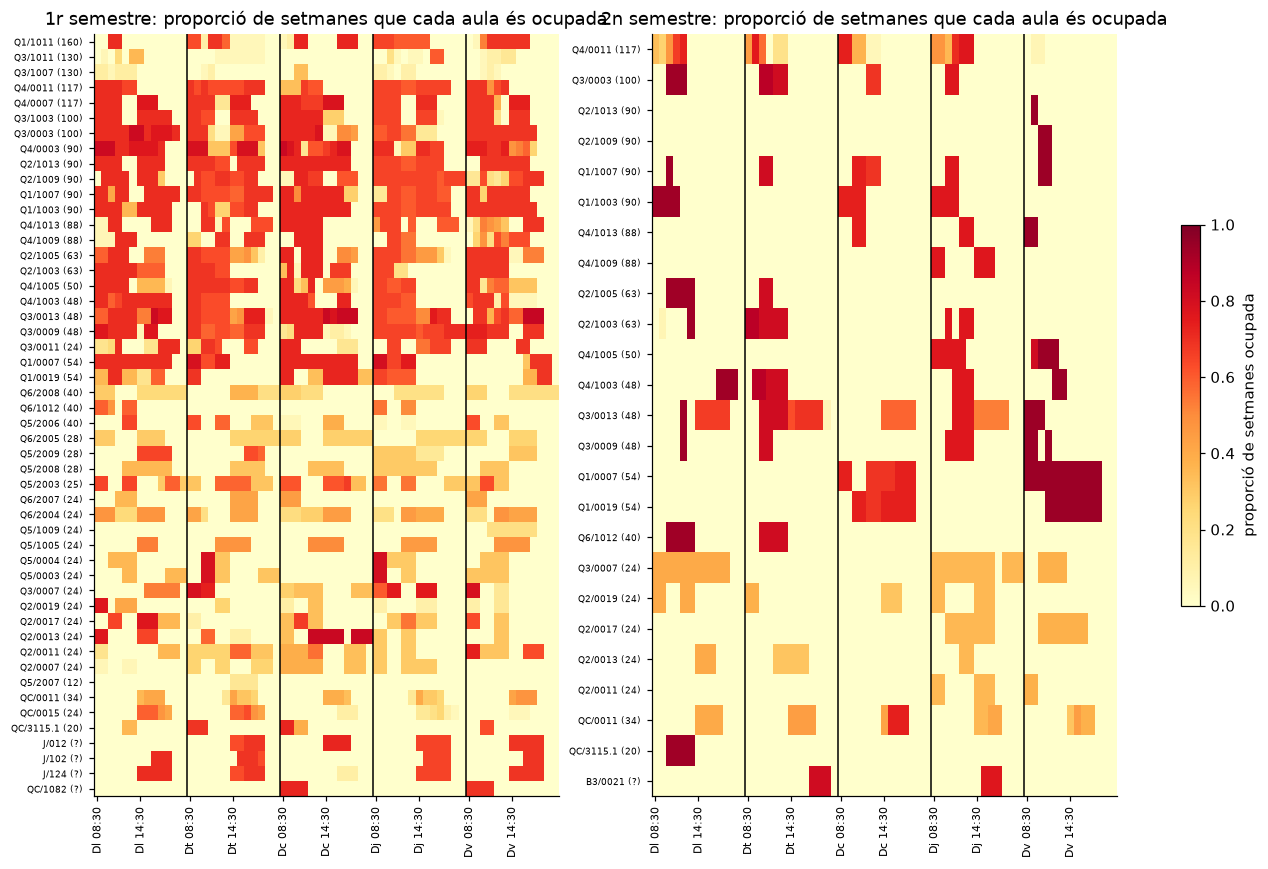

In [2]:
def mapa_calor(o, titol, ax):
    im = ax.imshow(o.values, aspect='auto', cmap='YlOrRd', vmin=0, vmax=1)
    ax.set_yticks(range(len(o)), [f"{r} ({int(c) if c == c else '?'})" for r, c in
                                  zip(o.index, a.set_index('aula')['capacitat'].reindex(o.index))], fontsize=6)
    xt = [i for i, (d, f) in enumerate(o.columns) if f in (FRANGES[0], MATI_FI)]
    ax.set_xticks(xt, [f"{NOM_DIA[o.columns[i][0]]} {fmt(o.columns[i][1])}" for i in xt], fontsize=7, rotation=90)
    for i, (d, f) in enumerate(o.columns):
        if f == FRANGES[0] and i:
            ax.axvline(i - .5, color='k', lw=1)
    ax.set_title(titol)
    return im

fig, axs = plt.subplots(1, 2, figsize=(15, 9))
for smt, ax in zip((1, 2), axs):
    im = mapa_calor(ocupacio_aules(s, a, smt), f'{smt}r semestre: proporció de setmanes que cada aula és ocupada'
                    if smt == 1 else f'{smt}n semestre: proporció de setmanes que cada aula és ocupada', ax)
fig.colorbar(im, ax=axs, shrink=.5, label='proporció de setmanes ocupada')
plt.show()

In [3]:
r1, r2 = resum_aules(s, a, 1), resum_aules(s, a, 2)
ord1, ord2 = r1[r1['tipus'] == 'Aules docents'], r2[r2['tipus'] == 'Aules docents']
print("Ocupació mitjana de les 21 aules ordinàries (segons l'aula que porten les dades):")
print(f"  1r semestre: matí {ord1['ocup_mati'].mean():.0%}, tarda {ord1['ocup_tarda'].mean():.0%}")
print(f"  2n semestre: matí {ord2['ocup_mati'].mean():.0%}, tarda {ord2['ocup_tarda'].mean():.0%}")
print('\nAules més plenes i més buides al 2n semestre:')
pd.concat([r2.head(5), r2[r2['tipus'] == 'Aules docents'].tail(5)]).round(2)

Ocupació mitjana de les 21 aules ordinàries (segons l'aula que porten les dades):
  1r semestre: matí 50%, tarda 27%
  2n semestre: matí 23%, tarda 4%

Aules més plenes i més buides al 2n semestre:


,ocup_mati,ocup_tarda,ocup_total,tipus,capacitat
aula,,,,,
Q3/0013,0.31,0.35,0.33,Aules docents,48.0
Q1/0007,0.28,0.24,0.26,Aules informàtiques,54.0
Q1/0019,0.19,0.24,0.22,Aules informàtiques,54.0
Q4/1003,0.28,0.08,0.17,Aules docents,48.0
Q4/0011,0.35,0.00,0.16,Aules docents,117.0
Q2/1005,0.18,0.00,0.08,Aules docents,63.0
Q4/1013,0.16,0.00,0.08,Aules docents,88.0
Q4/1009,0.05,0.07,0.06,Aules docents,88.0
Q2/1009,0.06,0.00,0.03,Aules docents,90.0


**Lectura:** al 1r semestre les aules semblen raonablement ocupades (les ordinàries, ~50 % al matí). Al 2n semestre
semblen gairebé buides (~22 % al matí, ~4 % a la tarda), i algunes aules de 90 places (Q2/1009, Q2/1013) semblen
sense ús. **No és real:** al 2n semestre la majoria de sessions no tenen aula a les dades, i aquí no surten.
L'apartat següent mesura la demanda real.

## 2. Sessions sense aula (2n semestre), i quantes aules necessiten

5.722 de les 7.739 sessions del 2n semestre (el 74 %) tenen `aula_partida` buida. No totes en necessiten:

necessita aula                             4541
PLAB (laboratori de departament, fixat)     919
doble titulació (no en necessita)           262 
Total sense aula: 5.722 de 7.739 (74%)


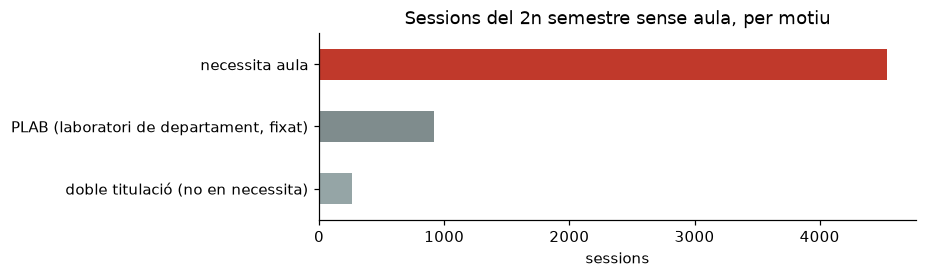

In [4]:
m = sense_aula(s, 2)
print(m.to_string(), f"\nTotal sense aula: {n(m.sum())} de {n(len(s2))} ({m.sum() / len(s2):.0%})")
ax = m.plot.barh(color=['#c0392b', '#7f8c8d', '#95a5a6'], figsize=(7, 2.2))
ax.set_xlabel('sessions'); ax.set_ylabel(''); ax.set_title('Sessions del 2n semestre sense aula, per motiu'); ax.invert_yaxis()
plt.show()

Per saber quantes aules calen de veritat comptem, per a cada data i franja horària, **quantes classes necessiten
una aula alhora** amb l'horari d'avui (amb aula a les dades o sense; una per classe física; sense PLAB, sense dobles
titulacions i sense les classes que es fan en un laboratori o aula d'informàtica).

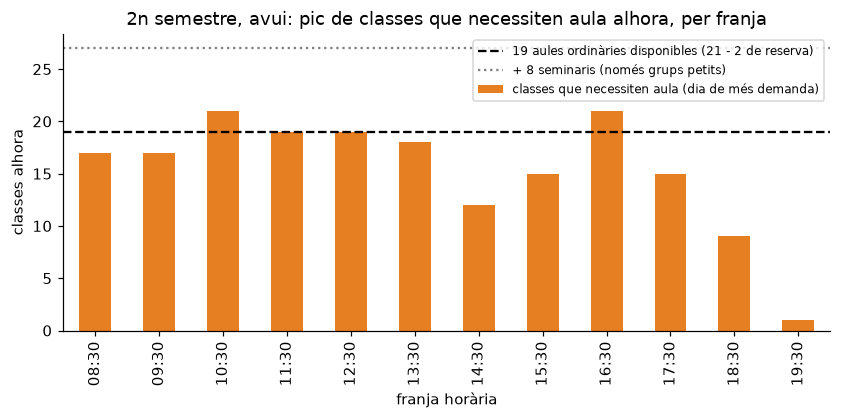

Franges (data x hora) per sobre de 19: 23 de 894; màxim 21 classes alhora


,data,dia,franja,total,amb_aula,sense_aula
14,2027-02-02,M,630,21,8,13
248,2027-03-02,M,990,21,3,18
191,2027-02-23,M,990,21,3,18
564,2027-04-21,X,990,21,2,19
497,2027-04-13,M,990,21,3,18
362,2027-03-16,M,990,21,2,19


In [5]:
g2 = simultanies(s, 2)
pic = g2.groupby('franja')[['total', 'amb_aula', 'sense_aula']].max()
pic.index = [fmt(f) for f in pic.index]
ax = pic['total'].plot.bar(color='#e67e22', figsize=(9, 3.5), label="classes que necessiten aula (dia de més demanda)")
ax.axhline(19, color='k', ls='--', label='19 aules ordinàries disponibles (21 - 2 de reserva)')
ax.axhline(19 + 8, color='grey', ls=':', label='+ 8 seminaris (només grups petits)')
ax.set_ylabel('classes alhora'); ax.set_xlabel('franja horària'); ax.legend(fontsize=8)
ax.set_title("2n semestre, avui: pic de classes que necessiten aula alhora, per franja")
plt.show()
sobre = g2[g2['total'] > 19]
print(f"Franges (data x hora) per sobre de 19: {len(sobre)} de {len(g2)}; màxim {g2['total'].max()} classes alhora")
sobre.sort_values('total', ascending=False).head(6)

**Lectura:** la demanda real es concentra **de 10.30 a 13.30 i a les 16.30**. Fins i tot avui, algunes franges
necessiten més que les 19 aules ordinàries disponibles (fins a 21): els grups petits han d'anar a seminaris. Les aules
que a l'apartat 1 semblen buides en realitat fan falta: simplement les dades no diuen quina sessió hi va.

## 3. Qui no és al seu torn?

Una sessió és fora de torn quan l'hora d'inici (abans o després de les 14.30) no quadra amb `torn_requerit`. A la
taula per titulació, una sessió compartida per dues cohorts compta per a totes dues. **Movible** = no fixada (fixades =
GEI i GEET+GEST de 1r i 2n, i els laboratoris PLAB: no es poden moure, i el verificador les marca com a heretades).

In [6]:
ft = s2['fora_torn']
mov = ft & (s2['fixada'] == '')
print(f"2n semestre: {n(ft.sum())} sessions fora de torn; {n(mov.sum())} movibles, {n((ft & (s2['fixada'] != '')).sum())} fixades")
print('Les movibles, segons on han d\'anar:', s2.loc[mov, 'torn_requerit'].map({'tarda': 'a la tarda', 'mati': 'al matí'}).value_counts().map(n).to_dict())
print(f"D'aquestes, {(mov & s2['doble']).sum()} són sessions de doble titulació que avui es fan amb un grup de matí (candidates a excepció)")
t = fora_de_torn(s, 2)
t = t[t['fora_torn'] > 0]
t

2n semestre: 3.246 sessions fora de torn; 2.008 movibles, 1.238 fixades
Les movibles, segons on han d'anar: {'a la tarda': '1.774', 'al matí': '234'}
D'aquestes, 248 són sessions de doble titulació que avui es fan amb un grup de matí (candidates a excepció)


,titulacio,curs_c,sessions,fora_torn,fora_torn_movibles,torn_requerit,pct_fora_torn
14,GEI,3r,1381,1232,883,tarda,89.2
15,GEI,4t,1217,1125,776,tarda,92.4
23,GEST,3r,527,521,497,tarda,98.9
13,GEI,2n,1168,406,0,mati/tarda,34.8
12,GEI,1r,998,328,0,mati/tarda,32.9
10,GEET,3r,238,232,208,tarda,97.5
19,GEQ,3r,163,163,163,tarda,100.0
1,GCIS,2n,124,124,124,mati,100.0
24,GEST,4t,112,112,112,tarda,100.0
25,GIA,1r,110,110,70,mati,100.0


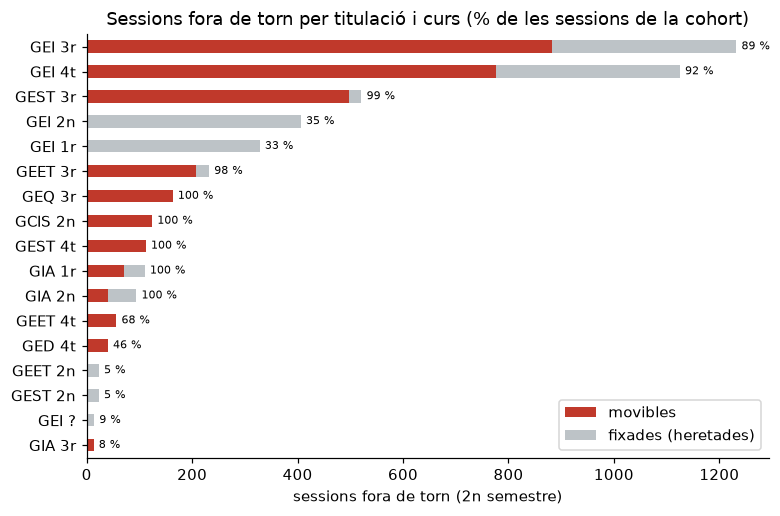

In [7]:
t2 = t.assign(cohort=t['titulacio'] + ' ' + t['curs_c']).set_index('cohort')
t2['fixades'] = t2['fora_torn'] - t2['fora_torn_movibles']
ax = t2[['fora_torn_movibles', 'fixades']].rename(columns={'fora_torn_movibles': 'movibles', 'fixades': 'fixades (heretades)'}) \
    .plot.barh(stacked=True, color=['#c0392b', '#bdc3c7'], figsize=(8, 5))
for i, (total, p) in enumerate(zip(t2['fora_torn'], t2['pct_fora_torn'])):
    ax.text(total + 10, i, f'{p:.0f} %', va='center', fontsize=7)
ax.invert_yaxis(); ax.set_xlabel('sessions fora de torn (2n semestre)'); ax.set_ylabel('')
ax.set_title('Sessions fora de torn per titulació i curs (% de les sessions de la cohort)')
plt.show()

**Lectura:** el canvi és sobretot **3r i 4t que passen a la tarda**: GEI 3r i 4t (~90 % de les seves sessions),
GEST 3r (99 %), GEET 3r (98 %), GEQ 3r (100 %). En sentit contrari, GCIS 2n i GIA 1r i 2n avui són del tot a la tarda
i han de venir al matí.

Les **fixades** són un límit estructural del model: els grups de GEI de 1r i 2n que avui són a la tarda «no es
toquen», i per tant es queden fora de torn (600 sessions de classe); i els laboratoris PLAB fixats es queden on són
(els de GEI 3r i 4t al matí, els de GIA 1r i 2n a la tarda). El verificador no els compta (heretats), però són
excepcions reals a la regla 1:

In [8]:
f = s2[s2['fora_torn'] & (s2['fixada'] != '')]
f.groupby(['titulacions_curs', 'tipus', 'torn_requerit']).size().rename('sessions fixades fora de torn') \
    .reset_index().sort_values('sessions fixades fora de torn', ascending=False)

,titulacions_curs,tipus,torn_requerit,sessions fixades fora de torn
9,GEI:3r|GEI:4t,PLAB,tarda,349
2,GEI:1r,PAUL,mati,236
5,GEI:2n,PAUL,mati,186
7,GEI:2n,PLAB,mati,98
8,GEI:2n,TE,mati,95
12,GIA:2n,PLAB,mati,54
3,GEI:1r,PLAB,mati,50
4,GEI:1r,TE,mati,42
11,GIA:1r,PLAB,mati,40
6,GEI:2n,PAUL,tarda,27


## 4. Hi cap el matí?

Si tot 1r i 2n va al matí, comparem les **hores-aula que es demanen** amb les **hores-aula que s'ofereixen**:
19 aules × 6 hores × dies lectius de la setmana. Dues definicions de la demanda:

- **només aula** (la nostra): classes que necessiten una aula ordinària o un seminari. Les que avui es fan en una
  aula d'informàtica o un laboratori integrat s'hi poden quedar.
- **definició de l'enunciat**: totes les sessions de 1r i 2n excepte PLAB i dobles titulacions (dona el 67-70 % que
  cita l'enunciat).

«Setmana normal» = 5 dies lectius i cap esdeveniment a `calendari.csv` (ni festiu, ni aturada, ni avaluació).

Setmanes normals (11): ús del matí 59,1-64,4 % (només aula), 64,4-69,6 % (definició de l'enunciat); avui, només amb les que ja són al matí: 46,5-51,8 %


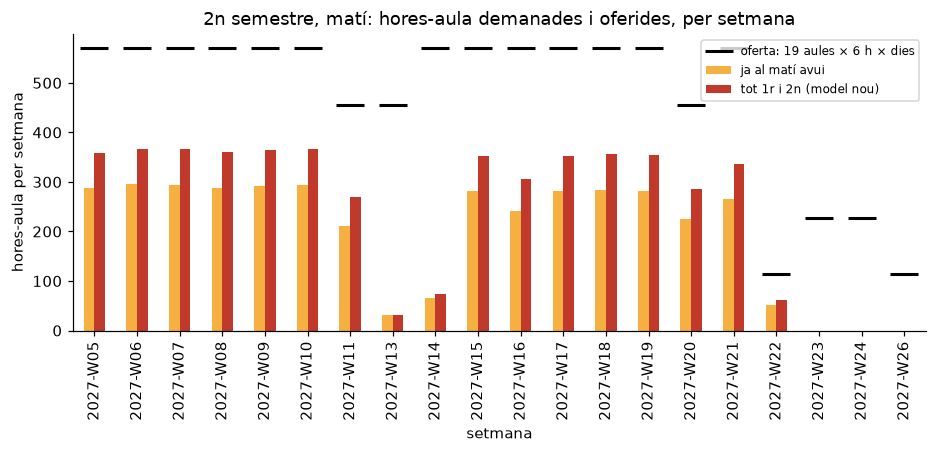

Tarda (3r, 4t, màsters; 19 aules × 6,5 h): 34,8-39,5 % a les setmanes normals


In [9]:
h = hores_aula_setmana(s, 2, 'mati')
normals = h[h['normal']]
h_en = (demanda_aula(s2, inclou_practiques=True).query("torn_requerit == 'mati'").groupby('setmana')['durada_min'].sum() / 60)
normals = normals.assign(enunciat_pct=(100 * h_en.reindex(normals.index) / normals['oferta_h']).round(1))
print(f"Setmanes normals ({len(normals)}): ús del matí {d(normals['ocupacio_pct'].min())}-{d(normals['ocupacio_pct'].max())} % (només aula), "
      f"{d(normals['enunciat_pct'].min())}-{d(normals['enunciat_pct'].max())} % (definició de l'enunciat); "
      f"avui, només amb les que ja són al matí: {d(normals['ocupacio_ja_al_torn_pct'].min())}-{d(normals['ocupacio_ja_al_torn_pct'].max())} %")
ax = h[['demanda_ja_al_torn_h', 'demanda_h']].rename(columns={'demanda_ja_al_torn_h': 'ja al matí avui',
                                                              'demanda_h': 'tot 1r i 2n (model nou)'}) \
    .plot.bar(figsize=(10, 3.5), color=['#f5b041', '#c0392b'])
ax.plot(range(len(h)), h['oferta_h'], 'k_', ms=18, mew=2, label='oferta: 19 aules × 6 h × dies')
ax.set_ylabel('hores-aula per setmana'); ax.set_xlabel('setmana'); ax.legend(fontsize=8)
ax.set_title("2n semestre, matí: hores-aula demanades i oferides, per setmana")
plt.show()
h_t = hores_aula_setmana(s, 2, 'tarda')
print(f"Tarda (3r, 4t, màsters; 19 aules × 6,5 h): {d(h_t.loc[h_t['normal'], 'ocupacio_pct'].min())}-"
      f"{d(h_t.loc[h_t['normal'], 'ocupacio_pct'].max())} % a les setmanes normals")

Les hores-aula són una mitjana. El que de veritat limita és el **pic**: quantes classes alhora. Amb les hores d'avui,
les classes de 1r i 2n que ja són al matí arriben a **15 alhora** (enunciat: «15 de 19»). Les que vénen de la tarda
encara no tenen hora (és la tasca del 5.2), però el total setmanal ens diu la mitjana que deixen:

Setmana 2027-W06: 367 hores-aula de classes de matí = de mitjana 12,2 classes alhora en les 30 hores de matí (límit 19)
Per dia (mantenint els dies d'avui), classes alhora de mitjana: {'Dl': '11,7', 'Dt': '14,5', 'Dc': '10,8', 'Dj': '12,7', 'Dv': '11,5'}


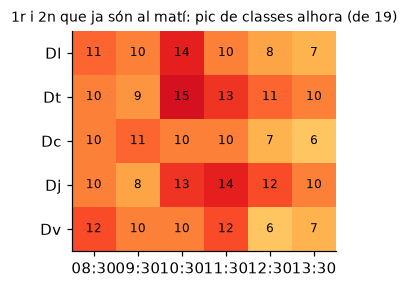

In [10]:
w = '2027-W06'   # una setmana normal
dm = demanda_aula(s2[s2['setmana'] == w]).query("torn_requerit == 'mati'")
per_dia = (dm.groupby('dia')['durada_min'].sum() / 60).reindex(DIES)
print(f"Setmana {w}: {dm['durada_min'].sum() / 60:.0f} hores-aula de classes de matí = de mitjana "
      f"{d(round(dm['durada_min'].sum() / 60 / 30, 1))} classes alhora en les 30 hores de matí (límit 19)")
print("Per dia (mantenint els dies d'avui), classes alhora de mitjana:", (per_dia / 6).round(1).rename(NOM_DIA).map(d).to_dict())
gm = simultanies(s, 2, lambda x: (x['torn_requerit'] == 'mati') & (x['torn_actual'] == 'mati'))
p = gm.groupby(['dia', 'franja'])['total'].max().unstack().reindex(DIES)
fig, ax = plt.subplots(figsize=(6, 2.6))
im = ax.imshow(p.values, cmap='YlOrRd', vmin=0, vmax=19)
for i in range(p.shape[0]):
    for j in range(p.shape[1]):
        ax.text(j, i, int(p.values[i, j]), ha='center', va='center', fontsize=8)
ax.set_xticks(range(p.shape[1]), [fmt(f) for f in p.columns]); ax.set_yticks(range(5), [NOM_DIA[x] for x in DIES])
ax.set_title('1r i 2n que ja són al matí: pic de classes alhora (de 19)', fontsize=9)
plt.show()

**I la mida de les aules?** Comprovació de recompte per a la mateixa setmana: per a cada mida d'aula N, les classes
de matí que necessiten com a mínim N places davant de les aules que en tenen com a mínim N (les 2 de reserva, preses
de les més petites). Si per a alguna N la demanda superés l'oferta, el matí no hi cabria fos quin fos l'horari.

,places_minim,classes_de_mes_de,aules_disponibles,demanda_h,oferta_h,us_pct
0,48,0,19,367.0,570,64.4
1,50,48,17,167.0,510,32.7
2,63,50,16,153.0,480,31.9
3,88,63,14,96.0,420,22.9
4,90,88,12,41.0,360,11.4
5,100,90,7,36.0,210,17.1
6,117,100,5,22.0,150,14.7
7,130,117,3,2.0,90,2.2
8,160,130,1,0.0,30,0.0


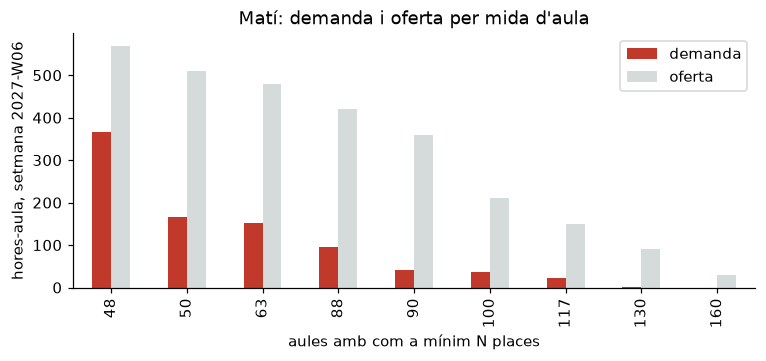

In [11]:
mm = mida_mati(s, a, 2, w)
display(mm)
ax = mm.plot.bar(x='places_minim', y=['demanda_h', 'oferta_h'], color=['#c0392b', '#d5dbdb'], figsize=(8, 3))
ax.legend(['demanda', 'oferta'])
ax.set_xlabel('aules amb com a mínim N places'); ax.set_ylabel('hores-aula, setmana ' + w)
ax.set_title('Matí: demanda i oferta per mida d\'aula')
plt.show()

**Lectura:** **sí, el matí hi cap, però el marge el marca el pic, no el total.** El model nou fa servir el 59-64 %
de les hores-aula de matí a les setmanes normals (64-70 % amb la definició de l'enunciat), i cap mida d'aula passa
del 33 % de les aules prou grans. Cada subgrup d'alumnes té com a molt 20 h de classe a la setmana davant de les 30
hores de matí. El risc és el dimarts i les franges de 10.30 a 13.30, que avui ja són a 13-15 de 19: les classes que
passen al matí s'han de repartir pels dies i les hores més tranquils (dimecres, divendres, 8.30). La tarda, en canvi,
es queda amb molta capacitat de sobres (~35-40 % d'ús).

## 5. Grups amb més alumnes que places a l'aula on són avui

Una classe física (alumnes d'una sessió compartida sumats) davant de la capacitat de l'aula, 2n semestre.

In [12]:
sa = sobre_aforament(s, a, 2)
print(f"{sa['sessions'].sum()} sessions de {len(sa)} grups per sobre de l'aforament; "
      f"{sa.loc[sa['fixada'] == '', 'sessions'].sum()} movibles (la resta són grups fixats de GEI: heretades)")
grans = a[a['ordinaria'] == 1].sort_values('capacitat', ascending=False)[['aula', 'capacitat']].head(6)
print('Aules ordinàries més grans:', ', '.join(f"{r.aula} ({r.capacitat})" for r in grans.itertuples()))
sa

101 sessions de 6 grups per sobre de l'aforament; 43 movibles (la resta són grups fixats de GEI: heretades)
Aules ordinàries més grans: Q1/1011 (160), Q3/1007 (130), Q3/1011 (130), Q4/0007 (117), Q4/0011 (117), Q3/0003 (100)


,codi,assignatura,grup,tipus,aula_partida,fixada,titulacions,sessions,alumnes,capacitat,excés
4,106043,Física,TE/21,TE,Q4/0011,,GEQ:1r,29,125,117,8
2,102750,Sistemes i Tecnologies Web,TE/450,TE,Q3/0003,,GEI:3r|GEI:4t,14,103,100,3
1,102746,Xarxes,PAUL/432,PAUL,Q3/0013,R1: GEI 2n,GEI:2n,15,50,48,2
0,102746,Xarxes,PAUL/431,PAUL,Q3/0009,R1: GEI 2n,GEI:2n,15,50,48,2
3,102775,Arquitectura de Computadors,PAUL/413,PAUL,Q4/1005,R1: GEI 2n,GEI:2n,15,52,50,2
5,107889,Disseny de Sistemes Digitals,PAUL/412,PAUL,Q3/0013,R1: GEI 1r,GEI:1r,13,49,48,1


**Lectura:** només hi ha dos grups movibles per sobre de l'aforament: **Física TE/21 (GEQ 1r), 125 alumnes a Q4/0011
(117 places)** i **Sistemes i Tecnologies Web TE/450 (GEI 3r i 4t), 103 a Q3/0003 (100)**. Tots dos tenen aules més
grans disponibles (Q1/1011 de 160, Q3/1007 i Q3/1011 de 130). Els altres quatre són grups PAUL fixats de GEI que
passen d'1 o 2 alumnes una aula de 48-50 places.

## 6. Pla contra realitat (setmana del 5 al 9 d'octubre de 2026)

L'Escola ha passat l'ocupació **real** de cada espai durant una setmana (llistat del GERES, Sigma):
`validacio/geres-ocupacio-setmana-2026-10-05.csv`. No és cap entrada del repte; serveix per contrastar les dades.
Preguntes:

1. **Cobertura:** quantes sessions del paquet d'aquella setmana surten de veritat al GERES?
2. **Es fan on diu el pla?** De les que al paquet tenen aula, quantes es fan a aquella aula?
3. **On es fan les que no tenen aula?** Al 2n semestre el 35 % de les sessions no en tenen. El GERES és d'una setmana
   del 1r semestre, on el paquet sí que té aula per a totes: aquesta pregunta només es podria respondre si en tinguessin
   alguna sense aula.
4. **Què no veu el pla?** Reserves que no són docència (actes, reunions...) que també ocupen aules.

Si el fitxer no hi és, aquest apartat ho diu i no fa res (vegeu `SETUP.md` per descarregar-lo).

In [13]:
v = carrega_validacio()
if v is None:
    print("No hi ha el fitxer validacio/geres-ocupacio-setmana-2026-10-05.csv: aquest apartat no es pot calcular.\n"
          "Descarregueu-lo de la carpeta del repte i poseu-lo a repte-horaris-escola/validacio/.")
else:
    cv = contrast_validacio(s, v)
    print(f"GERES: {n(cv['reserves'])} reserves ({n(cv['reserves_docents'])} docents, {n(cv['reserves_no_docents'])} no docents) "
          f"a {v['espai'].nunique()} espais")
    print(f"1. Cobertura: {n(cv['sessions_paquet_al_geres'])} de les {n(cv['sessions_paquet'])} sessions del paquet d'aquella setmana "
          f"surten al GERES ({cv['sessions_paquet_al_geres'] / max(cv['sessions_paquet'], 1):.0%}); "
          f"{cv['reserves_docents_sense_sessio']} reserves docents del GERES no tenen sessió al paquet")
    print(f"2. Mateixa aula: {n(cv['mateixa_aula'])} de {n(cv['enllacades_amb_aula_al_paquet'])} sessions amb aula al paquet "
          f"es fan a l'aula prevista ({cv['mateixa_aula'] / max(cv['enllacades_amb_aula_al_paquet'], 1):.0%})")
    print(f"3. Sense aula al paquet: {n(cv['enllacades_sense_aula_al_paquet'])} sessions surten al GERES amb un espai real")
    print(f"4. Reserves no docents: {d(round(cv['no_docents'].sum(), 1))} hores d'espai que el pla no veu")

GERES: 744 reserves (679 docents, 65 no docents) a 50 espais
1. Cobertura: 645 de les 769 sessions del paquet d'aquella setmana surten al GERES (84%); 33 reserves docents del GERES no tenen sessió al paquet
2. Mateixa aula: 645 de 646 sessions amb aula al paquet es fan a l'aula prevista (100%)
3. Sense aula al paquet: 0 sessions surten al GERES amb un espai real
4. Reserves no docents: 195,0 hores d'espai que el pla no veu


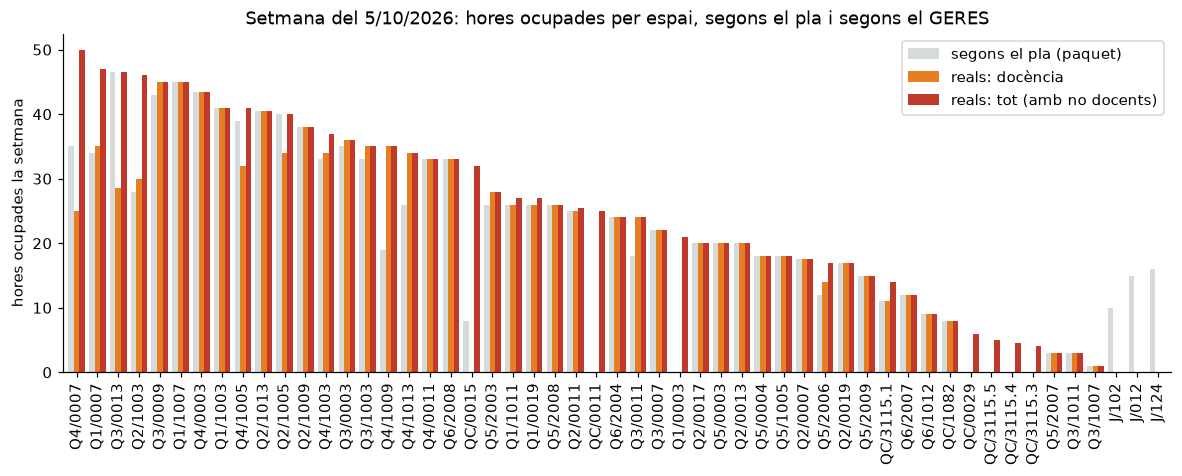

On es fan de veritat les sessions que al paquet no tenen aula (les 10 més freqüents):


,tipus,espai,sessions


Sessions que es fan en una aula diferent de la del paquet:


,id_sessio_paquet,aula_partida,espai,data,h_ini
630,S13031,Q1/0019,Q1/0007,2026-10-09,17:00


In [14]:
if v is not None:
    oc = cv['ocupacio']
    oc = oc[(oc['hores_pla'] > 0) | (oc['hores_reals_total'] > 0)].sort_values('hores_reals_total', ascending=False)
    ax = oc[['hores_pla', 'hores_reals_docents', 'hores_reals_total']] \
        .rename(columns={'hores_pla': 'segons el pla (paquet)', 'hores_reals_docents': 'reals: docència',
                         'hores_reals_total': 'reals: tot (amb no docents)'}) \
        .plot.bar(figsize=(13, 4), color=['#d5dbdb', '#e67e22', '#c0392b'], width=.8)
    ax.set_ylabel('hores ocupades la setmana'); ax.set_xlabel('')
    ax.set_title("Setmana del 5/10/2026: hores ocupades per espai, segons el pla i segons el GERES")
    plt.show()
    print('On es fan de veritat les sessions que al paquet no tenen aula (les 10 més freqüents):')
    display(cv['aula_real_de_les_sense_aula'].head(10))
    if len(cv['aula_diferent']):
        print("Sessions que es fan en una aula diferent de la del paquet:")
        display(cv['aula_diferent'])

**Lectura:** el paquet és una bona base. **El 84 % de les sessions d'aquella setmana (645 de 769) surten al GERES** i, de les 646 que s'enllacen amb una sessió amb aula, **645 es fan a l'aula prevista** (només una canvia: `Q1/0019` → `Q1/0007`, divendres 9/10 a les 17.00). Les 33 reserves docents del GERES sense sessió al paquet són grups fora del repte o canvis posteriors a l'extracte.

Sobre la pregunta 3: aquella setmana és del **1r semestre**, i el paquet hi té aula per a totes les sessions, així que no hi ha cap sessió «sense aula» per contrastar. Per tant **el GERES no ens diu on van les sessions del 2n semestre sense aula**: aquest buit del 35 % continua sent una dada que cal resoldre amb el nostre model, no una confirmació que les classes ja tinguin lloc.

**Reserves no docents:** 65 reserves, **195 hores d'espai** la setmana que el pla no veu (actes, reunions...). Són hores d'aula ocupades igualment: un motiu més per mantenir les dues aules de reserva de la regla 8.

**Limitacions** (del `LLEGIU-ME` de `validacio/`): és una sola setmana de classes normals del 1r semestre, i l'ocupació real pot incloure canvis d'aula posteriors a l'extracte de Sigma. Les xifres de cobertura (645) difereixen en 4 de les del `LLEGIU-ME` (649) perquè aquí només comptem sessions del paquet enllaçades per `id_sessio_paquet`.